# Split conformal prediction: calibrating prediction intervals

Continue from [Prediction intervals and coverage](../prediction-intervals/README.md).

## Learning goals

Build a prediction interval using held-out residuals, understand the finite-sample rank correction, and distinguish marginal coverage from coverage in specific input regions. This standalone educational example uses synthetic data and established methods; it contains no dissertation code.

## 1. Keep three roles separate

**Training** fits the predictor. **Calibration** sets the interval width. **Test** evaluates the final procedure. Choose the model and error level before examining calibration or test outcomes. Hyperparameter selection belongs inside the training portion. Refitting on calibration data after calculating the threshold invalidates this construction.

We deliberately fit a straight line to a nonlinear mean. Conformal prediction does not require a correct regression model for marginal validity under the assumptions below, but a poor predictor can produce unnecessarily wide intervals.

## 2. Turn prediction errors into scores

Let $\widehat f$ be the predictor fitted using training data only. For calibration pair $(X_i,Y_i)$, define

$$
R_i=|Y_i-\widehat f(X_i)|,\qquad i=1,\ldots,m.
$$

Here $m$ is the calibration sample size. A larger score means a larger prediction error. Sort these scores as $R_{(1)}\le\cdots\le R_{(m)}$.

For target miscoverage $\alpha$ (for example, $\alpha=0.10$ for 90% coverage), set

$$
k=\left\lceil(m+1)(1-\alpha)\right\rceil.
$$

The ceiling rounds upward. Use the actual order statistic, without interpolation:

$$
\widehat q=\begin{cases}R_{(k)},&k\le m,\\+\infty,&k=m+1.\end{cases}
$$

**Worked example:** with $m=199$ and $\alpha=0.10$, $k=180$. Use the 180th smallest absolute residual, which is element 179 in a zero-indexed sorted Python array. With $m=8$ and $\alpha=0.10$, $k=9$ and the valid interval is unbounded. Do not silently replace it with the largest available residual.

## 3. Construct a future-response interval

$$
C(x)=[\widehat f(x)-\widehat q,\;\widehat f(x)+\widehat q].
$$

Its width is $2\widehat q$ everywhere. This interval targets one future observed response, including observation noise. It is not an interval for the unknown mean function.

## 4. What is guaranteed?

Conditional on the training data, assume the calibration pairs and the future pair are exchangeable: their joint distribution is unchanged by permutation. Independent observations from the same distribution satisfy this assumption. With the predictor fixed using training data only,

$$
\Pr\{Y_{\mathrm{new}}\in C(X_{\mathrm{new}})\}\ge 1-\alpha.
$$

The probability averages over calibration data and the future pair (and may also average over training data). It is not a claim of 90% coverage for each realized calibration set, each fixed input, or every subgroup. It also does not guarantee simultaneous coverage of all future observations. Arbitrary distribution shifts or dependent time series need additional analysis.

**Why the correction works:** when scores have no ties, the future score's rank among $m+1$ exchangeable scores is uniform. The first $k$ ranks are covered, giving $k/(m+1)\ge1-\alpha$. Ties can make the procedure conservative. The unbounded case covers every finite response.

## 5. Experiment

Generate independent pairs with $X$ uniform on $[-1,1]$, standard-normal $\varepsilon$ independent of $X$, and

$$
Y=\sin(\pi X)+\sigma(X)\varepsilon,\qquad \sigma(x)=0.15+0.65\frac{x+1}{2}.
$$

Noise grows from left to right. Fit an intercept and slope to 120 training pairs, calibrate on 199 fresh pairs, and evaluate on 5,000 independent test pairs. Both model misspecification and changing noise are intentional.

Test coverage and average width are

$$
\widehat c=\frac{1}{N}\sum_{j=1}^{N}\mathbf 1\{L_j\le Y_j\le U_j\},\qquad
\overline w=\frac{1}{N}\sum_{j=1}^{N}(U_j-L_j).
$$

Here $N$ is test size; $L_j,U_j$ are interval endpoints. The indicator equals one for a captured response. Repeat the entire train/calibrate/test procedure 500 times, using one fresh future pair per repetition. These independent success indicators estimate marginal coverage; their Monte Carlo standard error is $\sqrt{\widehat c(1-\widehat c)/500}$. Test points sharing one calibration set are not independent replications of the full procedure.


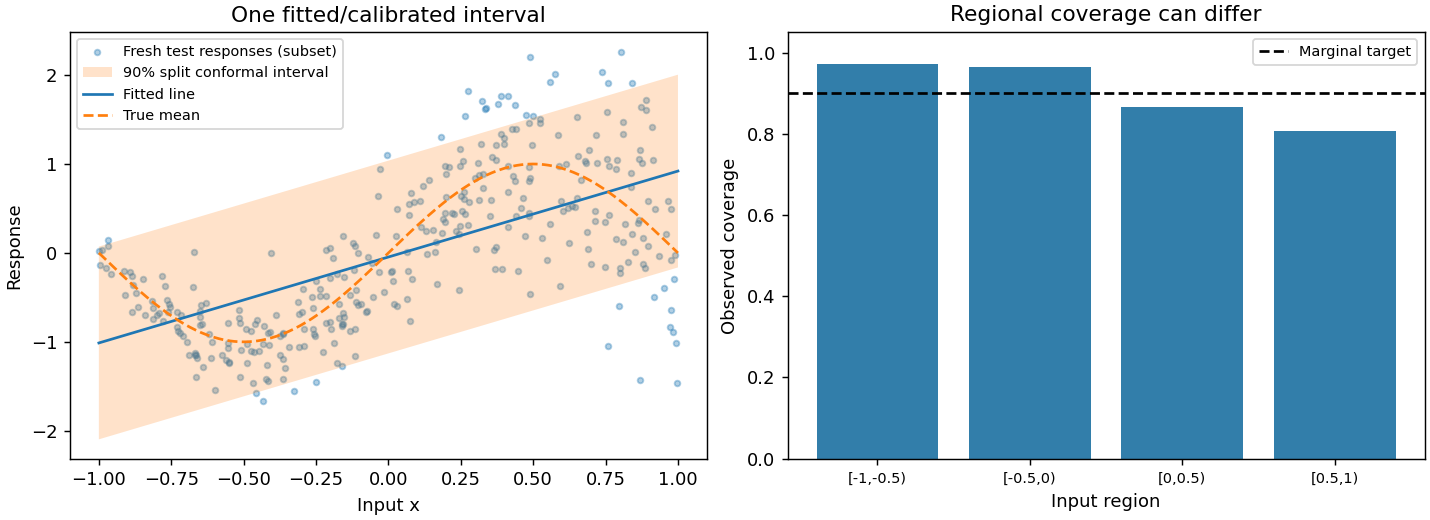

Single split: coverage=0.9008, width=2.1676
Region [-1.0, -0.5): n=1217, coverage=0.9729
Region [-0.5, 0.0): n=1220, coverage=0.9648
Region [0.0, 0.5): n=1279, coverage=0.8663
Region [0.5, 1.0): n=1284, coverage=0.8061
Independent repetitions: B=500, coverage=0.9200, MCSE=0.0121
95% exact binomial interval: [0.8927, 0.9422]
Average width across repetitions: 2.1926
Rank, boundary, tie, input-validation, and finite-width checks passed.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binomtest

ALPHA = 0.10

def threshold(scores, alpha):
    scores = np.asarray(scores, dtype=float)
    if scores.ndim != 1 or scores.size == 0:
        raise ValueError("Supply a nonempty one-dimensional score array")
    if not np.all(np.isfinite(scores)) or np.any(scores < 0):
        raise ValueError("Scores must be finite and nonnegative")
    if not 0 < alpha < 1:
        raise ValueError("alpha must be between zero and one")
    k = int(np.ceil((len(scores) + 1) * (1 - alpha)))
    return np.inf if k > len(scores) else np.sort(scores)[k - 1]

def sample(rng, n):
    x = rng.uniform(-1, 1, n)
    y = np.sin(np.pi * x) + (0.15 + 0.65 * (x + 1) / 2) * rng.normal(size=n)
    return x, y

def design(x):
    return np.column_stack([np.ones(len(x)), x])

def fit_and_calibrate(rng):
    xt, yt = sample(rng, 120)
    xc, yc = sample(rng, 199)
    beta = np.linalg.lstsq(design(xt), yt, rcond=None)[0]
    q = threshold(np.abs(yc - design(xc) @ beta), ALPHA)
    return beta, q

# Check exact rank, ties, and the small-calibration unbounded case.
assert threshold(np.arange(1, 200), 0.10) == 180
assert np.isinf(threshold(np.arange(8), 0.10))
assert threshold(np.ones(199), 0.10) == 1
for bad_scores, bad_alpha in [([], .1), ([np.nan], .1), ([-1], .1), ([1], 0)]:
    try:
        threshold(bad_scores, bad_alpha)
    except ValueError:
        pass
    else:
        raise AssertionError("Invalid input was accepted")

rng = np.random.default_rng(20261031)
beta, q = fit_and_calibrate(rng)
x, y = sample(rng, 5000)
mu = design(x) @ beta
covered = np.abs(y - mu) <= q
print(f"Single split: coverage={covered.mean():.4f}, width={2*q:.4f}")
edges = np.linspace(-1, 1, 5)
local = []
for left, right in zip(edges[:-1], edges[1:]):
    mask = (x >= left) & (x < right)
    local.append(covered[mask].mean())
    print(f"Region [{left:.1f}, {right:.1f}): n={mask.sum()}, coverage={local[-1]:.4f}")

grid = np.linspace(-1, 1, 300)
line = design(grid) @ beta
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].scatter(x[:350], y[:350], s=10, alpha=.35, label="Fresh test responses (subset)")
axes[0].fill_between(grid, line-q, line+q, alpha=.22, label="90% split conformal interval")
axes[0].plot(grid, line, label="Fitted line")
axes[0].plot(grid, np.sin(np.pi*grid), "--", label="True mean")
axes[0].set(xlabel="Input x", ylabel="Response", title="One fitted/calibrated interval")
axes[0].legend(fontsize=8)
axes[1].bar(["[-1,-0.5)", "[-0.5,0)", "[0,0.5)", "[0.5,1)"], local, color="#327eaa")
axes[1].axhline(.9, color="black", linestyle="--", label="Marginal target")
axes[1].set(ylim=(0,1.05), xlabel="Input region", ylabel="Observed coverage", title="Regional coverage can differ")
axes[1].tick_params(axis="x", labelsize=8)
axes[1].legend(fontsize=8)
plt.show()

# Independent datasets and one independent future pair for each repetition.
rep_rng = np.random.default_rng(20261101)
B = 500
hits = np.empty(B, dtype=bool)
widths = np.empty(B)
for b in range(B):
    beta_b, q_b = fit_and_calibrate(rep_rng)
    xb, yb = sample(rep_rng, 1)
    hits[b] = abs(yb[0] - (design(xb) @ beta_b)[0]) <= q_b
    widths[b] = 2*q_b
coverage = hits.mean()
mcse = np.sqrt(coverage*(1-coverage)/B)
ci = binomtest(int(hits.sum()), B).proportion_ci(method="exact")
print(f"Independent repetitions: B={B}, coverage={coverage:.4f}, MCSE={mcse:.4f}")
print(f"95% exact binomial interval: [{ci.low:.4f}, {ci.high:.4f}]")
print(f"Average width across repetitions: {widths.mean():.4f}")
assert np.isfinite(widths).all() and (widths >= 0).all()
print("Rank, boundary, tie, input-validation, and finite-width checks passed.")


## 6. Read the results carefully

The first plot shows one fitted/calibrated interval. Its width stays constant even where noise changes. Regional coverage in the second plot can vary substantially; these values describe this one split and are not population guarantees. The repeated experiment averages over new training and calibration sets. Its exact binomial interval describes simulation uncertainty in the procedure's marginal coverage, not uncertainty about a future response.

Simulation illustrates the theorem; it cannot prove it. A reported coverage below 0.90 in a finite run can occur from Monte Carlo variation. Better point prediction can improve efficiency, but conformal calibration does not remove bias or make the mean estimate correct.

## 7. Exercises

1. Change alpha to 0.05 in a fresh run. Explain the rank change and compare widths.
2. Increase calibration size. Which source of randomness does this reduce?
3. Replace the line by a cubic polynomial fitted only on training data. Compare widths over independent repetitions, keeping the test data out of model selection.
4. Set noise constant. Does constant interval width become more appropriate?

A future extension is a positive, training-fitted scale function: divide absolute residuals by that scale before calibration, then multiply the threshold by the scale at prediction time. This can adapt interval widths, but does not automatically give conditional coverage.

## References and reproducibility

- Oliveira, R. I., Orenstein, P., Ramos, T., and Romano, J. V. (2024). [Split Conformal Prediction and Non-Exchangeable Data](https://jmlr.org/papers/v25/23-1553.html). *Journal of Machine Learning Research*, 25(225), 1–38. Background and extensions; this tutorial uses the exchangeable setting with the explicit finite-sample rank correction.
- [SciPy exact binomial confidence intervals](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats._result_classes.BinomTestResult.proportion_ci.html).

Saved execution: Python 3.11+, NumPy 2.3.5, SciPy 1.17.0, Matplotlib 3.10.8. The repository requirements supply these dependencies. Fixed seeds reproduce this experiment in that environment; they do not establish validity for other data-generating processes. Newly written educational code and exposition prepared with AI assistance.
